# Project 6: Image Compression using Color Quantization (K-Means)

This project demonstrates color quantization on an image using the **K-Means clustering algorithm** from Scikit-Learn.
We compare original and quantized images across different values of $K$ ($K \in [2, 4, 8, 16, 32, 64]$) and analyze the trade-off between **visual quality (MSE)** and **file size (KB)**.

### 1. Import Libraries

In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

### 2. Load and Preprocess the Image

In [ ]:
image_path = '1.jpg'
img = cv2.imread(image_path)

img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

img_array = img.reshape((-1, 3))

print(f"Image shape: {img.shape}")
print(f"Reshaped array shape: {img_array.shape}")

Image shape: (1308, 736, 3)
Reshaped array shape: (962688, 3)


### 3. Visual Comparison Across Different Values of K ($K = 2 \dots 64$)

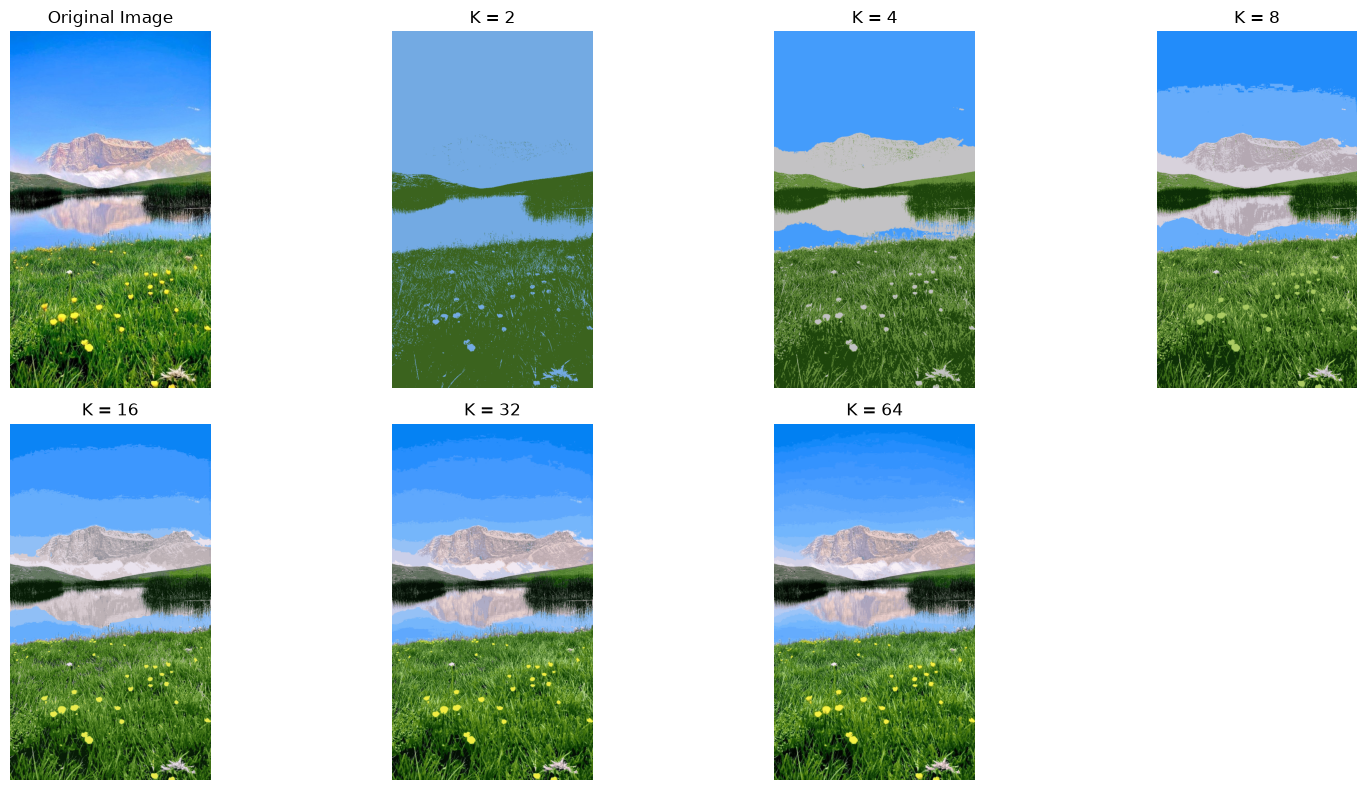

In [ ]:
k_values = [2, 4, 8, 16, 32, 64]

plt.figure(figsize=(16, 8))

plt.subplot(2, 4, 1)
plt.imshow(img)
plt.title("Original Image")
plt.axis('off')

for index, k in enumerate(k_values, start=2):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init='auto')
    kmeans.fit(img_array)
    
    compressed = kmeans.cluster_centers_[kmeans.labels_]
    compressed = np.clip(compressed.astype('uint8'), 0, 255)
    compressed_img = compressed.reshape(img.shape)
    
    plt.subplot(2, 4, index)
    plt.imshow(compressed_img)
    plt.title(f"K = {k}")
    plt.axis('off')

plt.tight_layout()
plt.show()

### 4. Quality vs. File Size Analysis (MSE & Size in KB)

In [ ]:
print(f"{'K':<6} | {'Size (KB)':<12} | {'Quality Loss (MSE)':<18}")
print("-" * 42)

cv2.imwrite("temp_original.jpg", cv2.cvtColor(img, cv2.COLOR_RGB2BGR))
orig_size = os.path.getsize("temp_original.jpg") / 1024
print(f"{'Orig':<6} | {orig_size:<12.2f} | {'0.00':<18}")

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init='auto')
    kmeans.fit(img_array)
    
    compressed = kmeans.cluster_centers_[kmeans.labels_]
    compressed = np.clip(compressed.astype('uint8'), 0, 255)
    compressed_img = compressed.reshape(img.shape)
    
    filename = f"temp_k_{k}.jpg"
    cv2.imwrite(filename, cv2.cvtColor(compressed_img, cv2.COLOR_RGB2BGR))
    size_kb = os.path.getsize(filename) / 1024
    
    mse = np.mean((img - compressed_img) ** 2)
    
    print(f"{k:<6} | {size_kb:<12.2f} | {mse:<18.2f}")
    
    if os.path.exists(filename):
        os.remove(filename)

if os.path.exists("temp_original.jpg"):
        os.remove("temp_original.jpg")

K      | Size (KB)    | Quality Loss (MSE)
------------------------------------------
Orig   | 435.83       | 0.00              
2      | 265.05       | 104.62            
4      | 416.52       | 87.01             
8      | 466.08       | 78.91             
16     | 475.13       | 64.42             
32     | 469.83       | 48.84             
64     | 462.64       | 32.63             
